In [1]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
from google.colab import files
uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [3]:
import os
import shutil

os.makedirs("/root/.kaggle", exist_ok=True)

shutil.copy(
    "/content/kaggle.json",
    "/root/.kaggle/kaggle.json"
)

os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Kaggle configured successfully!")

Kaggle configured successfully!


In [4]:
%pip -q install kaggle

In [5]:
!kaggle datasets download \
    -d sriramr/fruits-fresh-and-rotten-for-classification \
    -p /content/fruit_data \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/sriramr/fruits-fresh-and-rotten-for-classification
License(s): unknown
100% 3.58G/3.58G [00:27<00:00, 139MB/s]



In [6]:
import os

for root, dirs, files in os.walk("/content/fruit_data"):
    depth = root.replace("/content/fruit_data", "").count(os.sep)

    if depth <= 3:
        print(root, "| folders:", len(dirs), "| files:", len(files))

/content/fruit_data | folders: 1 | files: 0
/content/fruit_data/dataset | folders: 3 | files: 0
/content/fruit_data/dataset/test | folders: 6 | files: 0
/content/fruit_data/dataset/test/freshapples | folders: 0 | files: 395
/content/fruit_data/dataset/test/rottenbanana | folders: 0 | files: 530
/content/fruit_data/dataset/test/freshbanana | folders: 0 | files: 381
/content/fruit_data/dataset/test/rottenapples | folders: 0 | files: 601
/content/fruit_data/dataset/test/rottenoranges | folders: 0 | files: 403
/content/fruit_data/dataset/test/freshoranges | folders: 0 | files: 388
/content/fruit_data/dataset/dataset | folders: 2 | files: 0
/content/fruit_data/dataset/dataset/test | folders: 6 | files: 0
/content/fruit_data/dataset/dataset/train | folders: 6 | files: 0
/content/fruit_data/dataset/train | folders: 6 | files: 0
/content/fruit_data/dataset/train/freshapples | folders: 0 | files: 1693
/content/fruit_data/dataset/train/rottenbanana | folders: 0 | files: 2224
/content/fruit_data/

In [7]:
import tensorflow as tf
import os

DATA_DIR = "/content/fruit_data/dataset/dataset"

TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR = os.path.join(DATA_DIR, "test")

IMG_SIZE = (160, 160)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)

Found 10901 files belonging to 6 classes.
Using 8721 files for training.
Found 10901 files belonging to 6 classes.
Using 2180 files for validation.
Found 2698 files belonging to 6 classes.
Classes: ['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']
Number of classes: 6


In [8]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = tf.keras.Input(shape=(160, 160, 3))

x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.25)(x)
outputs = tf.keras.layers.Dense(
    num_classes,
    activation="softmax"
)(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [9]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[early_stop]
)

Epoch 1/5
273/273 ━━━━━━━━━━━━━━━━━━━━ 51s 142ms/step - accuracy: 0.9038 - loss: 0.2933 - val_accuracy: 0.9693 - val_loss: 0.0945
Epoch 2/5
273/273 ━━━━━━━━━━━━━━━━━━━━ 62s 99ms/step - accuracy: 0.9780 - loss: 0.0804 - val_accuracy: 0.9922 - val_loss: 0.0402
Epoch 3/5
273/273 ━━━━━━━━━━━━━━━━━━━━ 46s 117ms/step - accuracy: 0.9844 - loss: 0.0546 - val_accuracy: 0.9945 - val_loss: 0.0302
Epoch 4/5
273/273 ━━━━━━━━━━━━━━━━━━━━ 36s 99ms/step - accuracy: 0.9889 - loss: 0.0412 - val_accuracy: 0.9954 - val_loss: 0.0217
Epoch 5/5
273/273 ━━━━━━━━━━━━━━━━━━━━ 32s 117ms/step - accuracy: 0.9907 - loss: 0.0346 - val_accuracy: 0.9972 - val_loss: 0.0202


In [10]:
test_loss, test_acc = model.evaluate(test_ds)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc * 100:.2f}%")

85/85 ━━━━━━━━━━━━━━━━━━━━ 11s 135ms/step - accuracy: 0.9900 - loss: 0.0314
Test loss: 0.0314
Test accuracy: 99.00%


85/85 ━━━━━━━━━━━━━━━━━━━━ 16s 146ms/step
               precision    recall  f1-score   support

  freshapples       0.96      1.00      0.98       395
  freshbanana       1.00      1.00      1.00       381
 freshoranges       0.99      0.99      0.99       388
 rottenapples       0.99      0.97      0.98       601
 rottenbanana       1.00      1.00      1.00       530
rottenoranges       0.99      0.99      0.99       403

     accuracy                           0.99      2698
    macro avg       0.99      0.99      0.99      2698
 weighted avg       0.99      0.99      0.99      2698



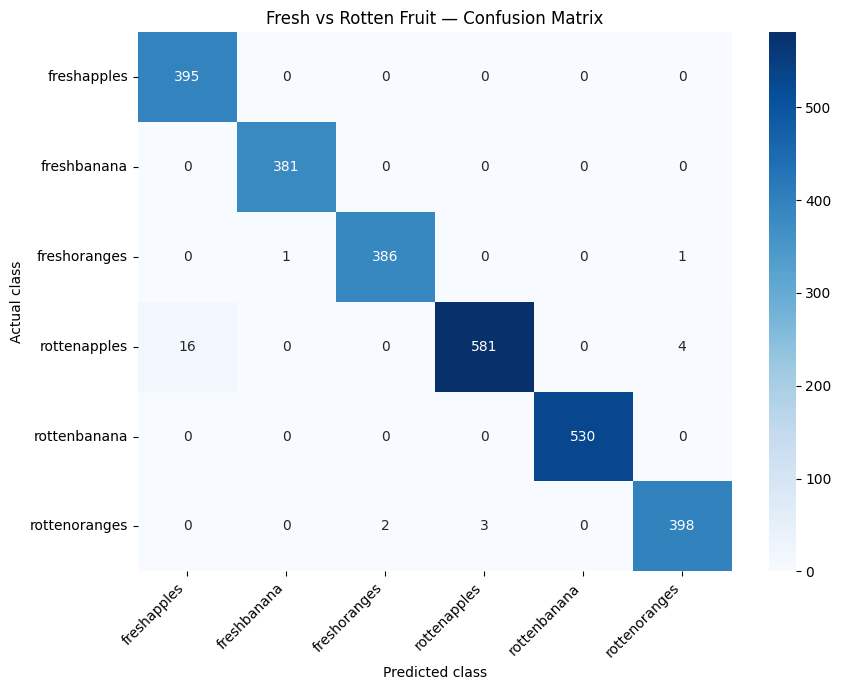

In [11]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(num_classes)),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(num_classes))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names,
    cmap="Blues"
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Fresh vs Rotten Fruit — Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [12]:
model.save("/content/fruit_fresh_rotten_mobilenetv2.keras")
print("Model saved successfully!")

Model saved successfully!


In [13]:
from google.colab import files
files.download("/content/fruit_fresh_rotten_mobilenetv2.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
import numpy as np
from sklearn.metrics import accuracy_score, recall_score

for fruit in ["apple", "banana", "orange"]:
    fresh_idx = next(
        i for i, c in enumerate(class_names)
        if fruit in c.lower() and "fresh" in c.lower()
    )
    rotten_idx = next(
        i for i, c in enumerate(class_names)
        if fruit in c.lower() and "rotten" in c.lower()
    )

    # Only evaluate images of this fruit type
    mask = np.isin(y_true, [fresh_idx, rotten_idx])
    actual = y_true[mask]
    predicted = y_pred[mask]

    actual_rotten = (actual == rotten_idx)
    predicted_rotten = (predicted == rotten_idx)

    condition_accuracy = accuracy_score(
        actual_rotten, predicted_rotten
    )
    rotten_recall = recall_score(
        actual_rotten, predicted_rotten, zero_division=0
    )

    missed_rotten = np.sum(
        actual_rotten & ~predicted_rotten
    )

    print(f"\n{fruit.upper()}")
    print(f"Fresh/rotten accuracy: {condition_accuracy:.4%}")
    print(f"Rotten recall: {rotten_recall:.4%}")
    print(f"Rotten images not predicted as rotten: {missed_rotten}")


APPLE
Fresh/rotten accuracy: 97.9920%
Rotten recall: 96.6722%
Rotten images not predicted as rotten: 20

BANANA
Fresh/rotten accuracy: 100.0000%
Rotten recall: 100.0000%
Rotten images not predicted as rotten: 0

ORANGE
Fresh/rotten accuracy: 99.2415%
Rotten recall: 98.7593%
Rotten images not predicted as rotten: 5


In [15]:
import os
import json
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

# Save the trained model
model.save("/content/fruit_fresh_rotten_mobilenetv2.keras")

# Save classification metrics
report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    "/content/classification_report.csv"
)

# Save confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
).to_csv("/content/confusion_matrix.csv")

# Save the main results
results = {
    "test_accuracy_percent": round(float(test_acc) * 100, 2),
    "test_loss": round(float(test_loss), 4),
    "classes": class_names,
    "test_images": int(len(y_true))
}

with open("/content/results.json", "w") as f:
    json.dump(results, f, indent=4)

print("Model and evaluation results saved!")

Model and evaluation results saved!


In [16]:
from google.colab import files

files.download("/content/fruit_fresh_rotten_mobilenetv2.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
files.download("/content/classification_report.csv")
files.download("/content/confusion_matrix.csv")
files.download("/content/results.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
import matplotlib.pyplot as plt
import numpy as np

wrong = np.where(y_true != y_pred)[0]

print("Total incorrect predictions:", len(wrong))

# Collect the test images into a batch list
test_batches = list(test_ds)

plt.figure(figsize=(14, 10))

for j, idx in enumerate(wrong[:12]):
    batch_idx = idx // 32
    item_idx = idx % 32

    images, labels = test_batches[batch_idx]

    plt.subplot(3, 4, j + 1)
    plt.imshow(images[item_idx].numpy().astype("uint8"))

    plt.title(
        f"Actual: {class_names[y_true[idx]]}\n"
        f"Predicted: {class_names[y_pred[idx]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

Total incorrect predictions: 27


KeyboardInterrupt: 

In [19]:
import pandas as pd

error_table = pd.crosstab(
    pd.Series(
        [class_names[i] for i in y_true],
        name="Actual"
    ),
    pd.Series(
        [class_names[i] for i in y_pred],
        name="Predicted"
    )
)

print("Misclassification counts (off-diagonal errors):")
for actual in class_names:
    for predicted in class_names:
        if actual != predicted:
            count = int(error_table.loc[actual, predicted])
            if count > 0:
                print(f"{actual} -> {predicted}: {count}")

Misclassification counts (off-diagonal errors):
freshoranges -> freshbanana: 1
freshoranges -> rottenoranges: 1
rottenapples -> freshapples: 16
rottenapples -> rottenoranges: 4
rottenoranges -> freshoranges: 2
rottenoranges -> rottenapples: 3


In [20]:
import numpy as np
import pandas as pd

wrong = np.where(y_true != y_pred)[0]

error_details = pd.DataFrame({
    "Actual": [class_names[y_true[i]] for i in wrong],
    "Predicted": [class_names[y_pred[i]] for i in wrong],
    "Confidence": [float(np.max(y_prob[i])) for i in wrong]
})

print("Lowest-confidence errors:")
print(error_details.sort_values("Confidence").to_string(index=False))

print("\nHighest-confidence errors:")
print(error_details.sort_values("Confidence", ascending=False).head(10).to_string(index=False))

Lowest-confidence errors:
       Actual     Predicted  Confidence
 rottenapples rottenoranges    0.416445
 rottenapples   freshapples    0.496158
 rottenapples   freshapples    0.533047
 rottenapples   freshapples    0.539825
 rottenapples   freshapples    0.545864
 rottenapples   freshapples    0.545969
 freshoranges   freshbanana    0.551061
 rottenapples   freshapples    0.556025
 rottenapples   freshapples    0.558647
 rottenapples   freshapples    0.561834
 rottenapples   freshapples    0.572721
 rottenapples rottenoranges    0.592518
 freshoranges rottenoranges    0.610188
 rottenapples   freshapples    0.612979
rottenoranges  freshoranges    0.668731
 rottenapples rottenoranges    0.677323
rottenoranges  rottenapples    0.679627
rottenoranges  rottenapples    0.713213
rottenoranges  freshoranges    0.732677
 rottenapples   freshapples    0.794727
rottenoranges  rottenapples    0.800682
 rottenapples   freshapples    0.815805
 rottenapples   freshapples    0.842002
 rottenapples 

In [21]:
# Keep the original baseline results for comparison
baseline_test_accuracy = float(test_acc)

# Unfreeze the base model's later layers
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen for stable fine-tuning
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Trainable layers:", sum(
    layer.trainable for layer in base_model.layers
))

Trainable layers: 19


In [22]:
fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=1,
            restore_best_weights=True
        )
    ]
)

Epoch 1/3
273/273 ━━━━━━━━━━━━━━━━━━━━ 50s 140ms/step - accuracy: 0.9931 - loss: 0.0230 - val_accuracy: 0.9977 - val_loss: 0.0088
Epoch 2/3
273/273 ━━━━━━━━━━━━━━━━━━━━ 66s 107ms/step - accuracy: 0.9956 - loss: 0.0138 - val_accuracy: 0.9913 - val_loss: 0.0216


In [23]:
fine_loss, fine_acc = model.evaluate(test_ds, verbose=0)

print(f"Baseline test accuracy: {baseline_test_accuracy * 100:.2f}%")
print(f"Fine-tuned test accuracy: {fine_acc * 100:.2f}%")

Baseline test accuracy: 99.00%
Fine-tuned test accuracy: 99.37%


In [24]:
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

# Get predictions from the fine-tuned model
y_prob_fine = model.predict(test_ds, verbose=1)
y_pred_fine = np.argmax(y_prob_fine, axis=1)

print("FINE-TUNED CLASSIFICATION REPORT")
print(classification_report(
    y_true,
    y_pred_fine,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

print("\nROTTEN FRUIT DETECTION")
for fruit in ["apple", "banana", "orange"]:
    rotten_idx = next(
        i for i, name in enumerate(class_names)
        if fruit in name.lower() and "rotten" in name.lower()
    )

    # Select all actual rotten fruit of this type
    mask = (y_true == rotten_idx)
    actual_rotten = y_true[mask]
    predicted_rotten = y_pred_fine[mask]

    missed = np.sum(predicted_rotten != rotten_idx)
    recall = np.mean(predicted_rotten == rotten_idx)

    print(f"{fruit.title()}:")
    print(f"  Rotten recall: {recall * 100:.2f}%")
    print(f"  Rotten fruit missed: {missed} / {len(actual_rotten)}")

cm_fine = confusion_matrix(
    y_true, y_pred_fine,
    labels=list(range(len(class_names)))
)

print("\nFine-tuned confusion matrix:")
print(pd.DataFrame(
    cm_fine,
    index=class_names,
    columns=class_names
))

85/85 ━━━━━━━━━━━━━━━━━━━━ 18s 128ms/step
FINE-TUNED CLASSIFICATION REPORT
               precision    recall  f1-score   support

  freshapples       0.98      1.00      0.99       395
  freshbanana       0.99      1.00      1.00       381
 freshoranges       0.99      0.99      0.99       388
 rottenapples       1.00      0.98      0.99       601
 rottenbanana       1.00      1.00      1.00       530
rottenoranges       1.00      0.99      0.99       403

     accuracy                           0.99      2698
    macro avg       0.99      0.99      0.99      2698
 weighted avg       0.99      0.99      0.99      2698


ROTTEN FRUIT DETECTION
Apple:
  Rotten recall: 98.17%
  Rotten fruit missed: 11 / 601
Banana:
  Rotten recall: 100.00%
  Rotten fruit missed: 0 / 530
Orange:
  Rotten recall: 99.01%
  Rotten fruit missed: 4 / 403

Fine-tuned confusion matrix:
               freshapples  freshbanana  freshoranges  rottenapples  \
freshapples            395            0             0    

In [25]:
model.save(
    "/content/fruit_fresh_rotten_mobilenetv2_finetuned.keras"
)
print("Fine-tuned model saved!")

Fine-tuned model saved!


In [26]:
import os
import json
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

OUT = "/content/PS12_results"
os.makedirs(OUT, exist_ok=True)

# Save the fine-tuned model
model.save(f"{OUT}/fruit_fresh_rotten_finetuned.keras")

# Save classification report
report = classification_report(
    y_true,
    y_pred_fine,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    f"{OUT}/classification_report.csv"
)

# Save confusion matrix
cm = confusion_matrix(
    y_true, y_pred_fine,
    labels=list(range(len(class_names)))
)

pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
).to_csv(f"{OUT}/confusion_matrix.csv")

# Save summary metrics
summary = {
    "baseline_test_accuracy_percent": 99.00,
    "fine_tuned_test_accuracy_percent": round(float(fine_acc) * 100, 2),
    "test_images": int(len(y_true)),
    "classes": class_names,
    "rotten_apples_missed": 11,
    "rotten_bananas_missed": 0,
    "rotten_oranges_missed": 4
}

with open(f"{OUT}/summary.json", "w") as f:
    json.dump(summary, f, indent=4)

print("Saved final model and evaluation files to:", OUT)
print(os.listdir(OUT))

Saved final model and evaluation files to: /content/PS12_results
['fruit_fresh_rotten_finetuned.keras', 'confusion_matrix.csv', 'classification_report.csv', 'summary.json']


In [27]:
!cd /content && zip -qr PS12_results.zip PS12_results

In [28]:
from google.colab import files
files.download("/content/PS12_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saving 1000_F_928439821_WEP2PJPYvMvV1qRuXX2zkFJ4nK5FMHBU.jpg to 1000_F_928439821_WEP2PJPYvMvV1qRuXX2zkFJ4nK5FMHBU.jpg


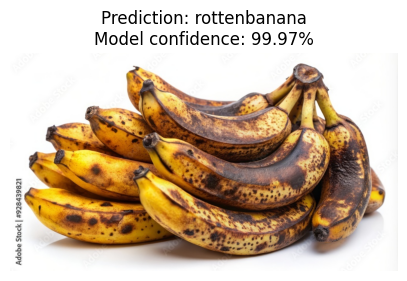

Predicted class: rottenbanana
Model confidence: 99.97%


In [35]:
from google.colab import files
from IPython.display import display
from PIL import Image
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

uploaded = files.upload()

for filename in uploaded:
    img = Image.open(filename).convert("RGB")
    img_resized = img.resize((160, 160))

    image_array = np.array(img_resized, dtype=np.float32)
    image_array = np.expand_dims(image_array, axis=0)

    probabilities = model.predict(image_array, verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))
    predicted_class = class_names[predicted_index]
    confidence = float(probabilities[predicted_index]) * 100

    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis("off")
    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Model confidence: {confidence:.2f}%"
    )
    plt.show()

    print("Predicted class:", predicted_class)
    print(f"Model confidence: {confidence:.2f}%")

## PS-12 Submission Checks

This section adds the evidence required by the assignment: class counts and examples, training curves, and error analysis for the final fine-tuned model.

**Security:** Do not upload `kaggle.json`, downloaded dataset files, or `.keras` model files to the public GitHub repository. The notebook uses a Kaggle credential upload only when run in Colab; keep the credential private.


In [ ]:
# 1. Number of images per class in each provided split
import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

def count_images_by_class(split_dir):
    supported = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
    counts = {}
    for class_name in sorted(os.listdir(split_dir)):
        class_dir = os.path.join(split_dir, class_name)
        if os.path.isdir(class_dir):
            counts[class_name] = sum(
                1 for name in os.listdir(class_dir)
                if name.lower().endswith(supported)
            )
    return counts

train_counts = count_images_by_class(TRAIN_DIR)
test_counts = count_images_by_class(TEST_DIR)
counts_df = pd.DataFrame({
    "Train folder (before validation split)": train_counts,
    "Test": test_counts
}).fillna(0).astype(int)
display(counts_df)
print("Train folder images:", sum(train_counts.values()))
print("Training images actually used:", 8721)
print("Validation images:", 2180)
print("Test images:", sum(test_counts.values()))
print("Note: 20% of the training folder is used for validation (seed=42). The provided test folder remains untouched.")


In [ ]:
# 2. Show sample images from all six classes
# Use the provided training folders, displaying up to three images per class.
supported = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
class_dirs = [
    name for name in sorted(os.listdir(TRAIN_DIR))
    if os.path.isdir(os.path.join(TRAIN_DIR, name))
]
fig, axes = plt.subplots(len(class_dirs), 3, figsize=(9, 3 * len(class_dirs)))
for row, class_name in enumerate(class_dirs):
    folder = os.path.join(TRAIN_DIR, class_name)
    paths = [
        os.path.join(folder, f) for f in sorted(os.listdir(folder))
        if f.lower().endswith(supported)
    ][:3]
    for col in range(3):
        ax = axes[row, col]
        ax.axis("off")
        if col < len(paths):
            with Image.open(paths[col]) as im:
                ax.imshow(im.convert("RGB"))
            ax.set_title(class_name)
plt.suptitle("Example images from each fruit-condition class", y=1.002)
plt.tight_layout()
plt.show()


In [ ]:
# 3. Training and validation curves
# Plot the frozen-backbone training and fine-tuning histories separately,
# because they use different learning rates and phases.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history.get("accuracy", []), marker="o", label="Train")
axes[0].plot(history.history.get("val_accuracy", []), marker="o", label="Validation")
axes[0].set_title("Initial training: accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history.get("loss", []), marker="o", label="Train")
axes[1].plot(history.history.get("val_loss", []), marker="o", label="Validation")
axes[1].set_title("Initial training: loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Sparse categorical cross-entropy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

if "fine_tune_history" in globals():
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(fine_tune_history.history.get("accuracy", []), marker="o", label="Train")
    axes[0].plot(fine_tune_history.history.get("val_accuracy", []), marker="o", label="Validation")
    axes[0].set_title("Fine-tuning: accuracy")
    axes[0].set_xlabel("Fine-tuning epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(fine_tune_history.history.get("loss", []), marker="o", label="Train")
    axes[1].plot(fine_tune_history.history.get("val_loss", []), marker="o", label="Validation")
    axes[1].set_title("Fine-tuning: loss")
    axes[1].set_xlabel("Fine-tuning epoch")
    axes[1].set_ylabel("Sparse categorical cross-entropy")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


In [ ]:
# 4. Final test-set metrics and confusion matrix (fine-tuned model)
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
import seaborn as sns
import numpy as np

# Reuse the final fine-tuned predictions generated in the earlier cell.
final_accuracy = accuracy_score(y_true, y_pred_fine)
final_macro_f1 = f1_score(y_true, y_pred_fine, average="macro")
print(f"Final test accuracy: {final_accuracy * 100:.2f}%")
print(f"Final macro F1: {final_macro_f1:.4f}")
print(classification_report(
    y_true, y_pred_fine,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
))
cm_final = confusion_matrix(y_true, y_pred_fine, labels=list(range(len(class_names))))
plt.figure(figsize=(9, 7))
sns.heatmap(cm_final, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Final fine-tuned model — test confusion matrix")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [ ]:
# 5. At least four misclassified test images from the FINAL fine-tuned model
# These are selected from the held-out test set, not the training/validation data.
wrong_final = np.where(y_true != y_pred_fine)[0]
print("Final-model misclassifications:", len(wrong_final))

# Use likely visual causes as hypotheses only; confirm them by inspecting each displayed image.
def likely_error_hypothesis(actual_name, predicted_name):
    if "rotten" in actual_name and "fresh" in predicted_name:
        return "Possible subtle/early spoilage, limited visible rot, or background/lighting cues."
    if "fresh" in actual_name and "rotten" in predicted_name:
        return "Possible blemish, shadow, uneven lighting, or appearance resembling spoilage."
    if "apple" in actual_name and "orange" in predicted_name:
        return "Possible colour/shape overlap or image/background cues."
    if "orange" in actual_name and "banana" in predicted_name:
        return "Possible unusual crop, occlusion, or background/shape cues."
    if "orange" in actual_name and "apple" in predicted_name:
        return "Possible colour/shape overlap, crop, or background cues."
    if "banana" in actual_name and "apple" in predicted_name:
        return "Possible unusual angle, occlusion, or background/shape cues."
    return "Inspect colour, visible damage, crop, lighting, occlusion, and background; this is a hypothesis, not a verified cause."

# Materialize test batches once so selected images can be displayed.
test_batches_for_errors = list(test_ds)
shown = min(8, len(wrong_final))
if shown == 0:
    print("No errors to display for this model on this test set.")
else:
    cols = 2
    rows = int(np.ceil(shown / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(12, 4.6 * rows))
    axes = np.array(axes).reshape(-1)
    for j, idx in enumerate(wrong_final[:shown]):
        batch_idx, item_idx = divmod(int(idx), BATCH_SIZE)
        images, labels = test_batches_for_errors[batch_idx]
        axes[j].imshow(images[item_idx].numpy().astype("uint8"))
        actual_name = class_names[int(y_true[idx])]
        predicted_name = class_names[int(y_pred_fine[idx])]
        confidence = float(np.max(y_prob_fine[idx])) * 100
        axes[j].set_title(
            f"Actual: {actual_name}\nPredicted: {predicted_name} ({confidence:.1f}%)",
            fontsize=10
        )
        axes[j].axis("off")
        print(
            f"Example {j+1}: actual={actual_name}; predicted={predicted_name}; "
            f"confidence={confidence:.2f}%. Likely cause to verify: "
            f"{likely_error_hypothesis(actual_name, predicted_name)}"
        )
    for ax in axes[shown:]:
        ax.axis("off")
    plt.suptitle("Misclassified examples — final fine-tuned model (test set)")
    plt.tight_layout()
    plt.show()


## Analysis and Discussion — notes for the report

The initial model achieved 99.00% test accuracy; fine-tuning increased it to 99.37%. The remaining errors are not distributed evenly: apples account for most errors, especially rotten apples predicted as fresh apples. This is important because a false-fresh prediction can allow spoiled fruit to pass sorting. The model may be using colour, lighting, background, or image composition as shortcuts instead of relying only on spoilage cues. The error images should be visually inspected before stating a specific cause; the explanations printed above are hypotheses, not ground-truth annotations.

**Limitations:** The test set appears to come from the same dataset source and may not represent real shop, warehouse, or phone-camera conditions. The model has not been validated on external images. Test performance alone does not prove robustness or eliminate shortcut learning.


## Dataset citation

Dataset: *Fruits Fresh and Rotten for Classification*, Kaggle, `sriramr/fruits-fresh-and-rotten-for-classification`: https://www.kaggle.com/datasets/sriramr/fruits-fresh-and-rotten-for-classification

Add the exact dataset paper citation if the dataset page specifies one. Declare AI-assistant use according to your course rules.
